# Exploratory Data Analysis (EDA)

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from config import config
from utils import plot_corr_matrix

%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [2]:
train = pd.read_csv(config.paths.train_data)
test = pd.read_csv(config.paths.test_data)
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Целевая переменная

Skeweness: 1.8828757597682118
Kurtosis: 6.536281860064525


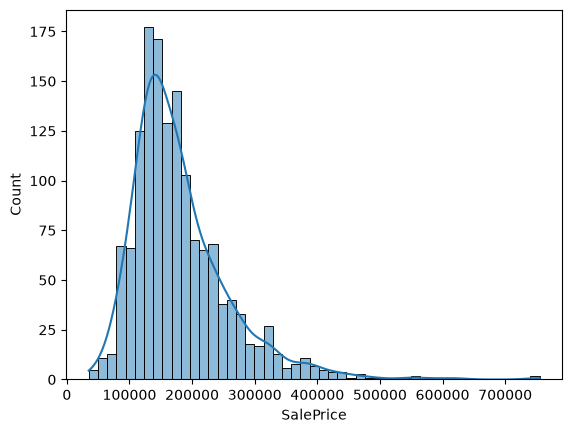

In [4]:
sns.histplot(train['SalePrice'], kde=True)

print(f'Skeweness: {train['SalePrice'].skew()}')
print(f'Kurtosis: {train['SalePrice'].kurt()}')

plt.show()

Распределение не нормальное. Сделаем логарифмическое преобразование, чтобы получить нормальное распределение:

Skeweness: 0.1213350622052098
Kurtosis: 0.8095319958036296


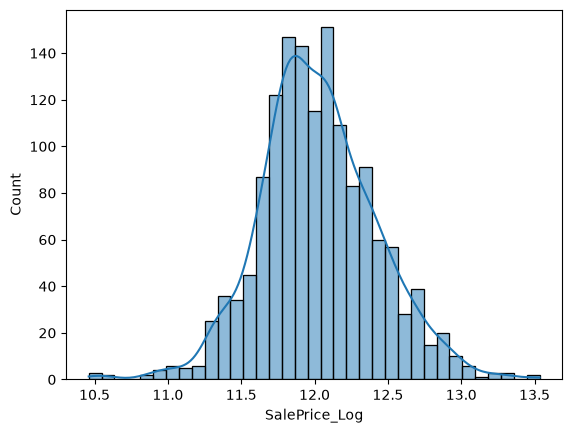

In [5]:
train['SalePrice_Log'] = np.log(train['SalePrice'])

sns.histplot(train['SalePrice_Log'], kde=True)

print(f'Skeweness: {train['SalePrice_Log'].skew()}')
print(f'Kurtosis: {train['SalePrice_Log'].kurt()}')

train.drop('SalePrice', axis=1, inplace=True)

plt.show()

## Численные и категориальные признаки

In [ ]:
numerical_features = train.select_dtypes(include='number').columns
print(f'Number of numerical features: {len(numerical_features)}')

categorical_features = train.select_dtypes(include=['str', 'object', 'category']).columns
print(f'Number of categorical features: {len(categorical_features)}')

Number of numerical features: 38
Number of categorical features: 43


In [7]:
train[numerical_features].head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice_Log
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,0,61,0,0,0,0,0,2,2008,12.247694
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,298,0,0,0,0,0,0,5,2007,12.109011
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,0,42,0,0,0,0,0,9,2008,12.317167
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,0,35,272,0,0,0,0,2,2006,11.849398
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,192,84,0,0,0,0,0,12,2008,12.429216


In [8]:
train[categorical_features].head()

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1,RL,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
3,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,...,Detchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Abnorml
4,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal


Посмотрим на количество и частоту пропущенных значений:

In [9]:
total_nans = train.isnull().sum().sort_values(ascending=False)
percent_nans = (train.isnull().sum() / train.isnull().count()).sort_values(ascending=False)

missing_data = pd.concat([total_nans, percent_nans], axis=1, keys=['Total', 'Rate'])
missing_data.head(20)

,Total,Rate
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
MasVnrType,872,0.597260
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageQual,81,0.055479
GarageFinish,81,0.055479
GarageType,81,0.055479


Для некоторых признаков NaN означает не отсутствие значение, а отсутствие предмета (забора, бассейна и т.д.) в доме. Заменим такие Nan на None. Для остальных признаков заменим NaN на среднее значение

In [10]:
cols_fillna = ['PoolQC','MiscFeature','Alley','Fence','MasVnrType','FireplaceQu',
               'GarageQual','GarageCond','GarageFinish','GarageType', 'Electrical',
               'KitchenQual', 'SaleType', 'Functional', 'Exterior2nd', 'Exterior1st',
               'BsmtExposure','BsmtCond','BsmtQual','BsmtFinType1','BsmtFinType2',
               'MSZoning', 'Utilities']

train[cols_fillna] = train[cols_fillna].fillna('None')
test[cols_fillna] = test[cols_fillna].fillna('None')

In [11]:
total_nans = train.isnull().sum().sort_values(ascending=False)
percent_nans = (train.isnull().sum() / train.isnull().count()).sort_values(ascending=False)

missing_data = pd.concat([total_nans, percent_nans], axis=1, keys=['Total', 'Rate'])
missing_data.head()

,Total,Rate
LotFrontage,259,0.177397
GarageYrBlt,81,0.055479
MasVnrArea,8,0.005479
Id,0,0.000000
MSSubClass,0,0.000000


In [12]:
numeric_means = train.mean(numeric_only=True)

train.fillna(numeric_means, inplace=True)
test.fillna(numeric_means, inplace=True)

total_nans = train.isnull().sum().sort_values(ascending=False)
percent_nans = (train.isnull().sum() / train.isnull().count()).sort_values(ascending=False)

missing_data = pd.concat([total_nans, percent_nans], axis=1, keys=['Total', 'Rate'])
missing_data.head()

,Total,Rate
Id,0,0.0
MSSubClass,0,0.0
MSZoning,0,0.0
LotFrontage,0,0.0
LotArea,0,0.0


In [13]:
train.isnull().sum().sum()

np.int64(0)

In [14]:
test.isnull().sum().sum()

np.int64(0)

В датасетах больше нет Nan. Теперь посмотрим, какие признаки не подчиняются нормальному распределению, и переведем их в логарифмическую шкалу

In [15]:
for col in numerical_features:
    print('{:15}'.format(col), 
          'Skewness: {:05.2f}'.format(train[col].skew()) , 
          '   ' ,
          'Kurtosis: {:06.2f}'.format(train[col].kurt())  
         )

Id              Skewness: 00.00     Kurtosis: -01.20
MSSubClass      Skewness: 01.41     Kurtosis: 001.58
LotFrontage     Skewness: 02.38     Kurtosis: 021.85
LotArea         Skewness: 12.21     Kurtosis: 203.24
OverallQual     Skewness: 00.22     Kurtosis: 000.10
OverallCond     Skewness: 00.69     Kurtosis: 001.11
YearBuilt       Skewness: -0.61     Kurtosis: -00.44
YearRemodAdd    Skewness: -0.50     Kurtosis: -01.27
MasVnrArea      Skewness: 02.68     Kurtosis: 010.15
BsmtFinSF1      Skewness: 01.69     Kurtosis: 011.12
BsmtFinSF2      Skewness: 04.26     Kurtosis: 020.11
BsmtUnfSF       Skewness: 00.92     Kurtosis: 000.47
TotalBsmtSF     Skewness: 01.52     Kurtosis: 013.25
1stFlrSF        Skewness: 01.38     Kurtosis: 005.75
2ndFlrSF        Skewness: 00.81     Kurtosis: -00.55
LowQualFinSF    Skewness: 09.01     Kurtosis: 083.23
GrLivArea       Skewness: 01.37     Kurtosis: 004.90
BsmtFullBath    Skewness: 00.60     Kurtosis: -00.84
BsmtHalfBath    Skewness: 04.10     Kurtosis: 

Skeweness: 1.3665603560164559
Kurtosis: 4.895120580693171


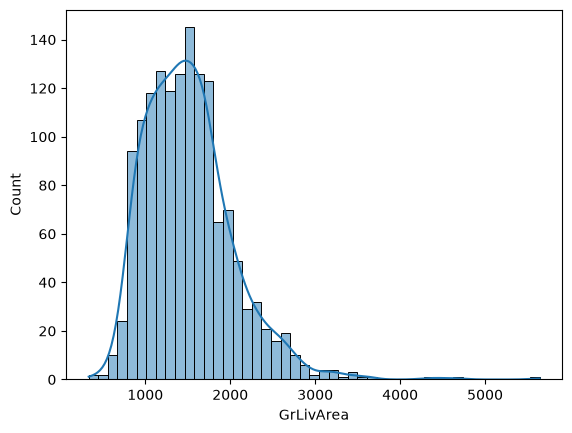

In [16]:
sns.histplot(train['GrLivArea'], kde=True)

print(f'Skeweness: {train['GrLivArea'].skew()}')
print(f'Kurtosis: {train['GrLivArea'].kurt()}')

plt.show()

Skeweness: 12.207687851233496
Kurtosis: 203.24327101886033


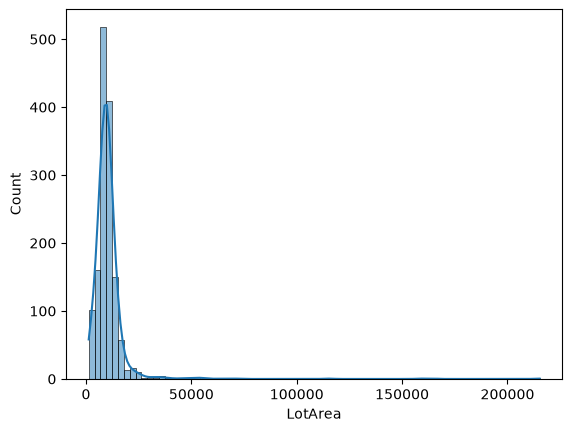

In [17]:
sns.histplot(train['LotArea'], kde=True)

print(f'Skeweness: {train['LotArea'].skew()}')
print(f'Kurtosis: {train['LotArea'].kurt()}')

plt.show()

In [18]:
for df in [train, test]:
    df['GrLivArea_Log'] = np.log1p(df['GrLivArea'])
    df['LotArea_Log'] = np.log1p(df['LotArea'])

    df.drop(columns=['GrLivArea', 'LotArea'], inplace=True)

numerical_features = train.select_dtypes(include='number').columns

Skeweness: -0.006140253486289682
Kurtosis: 0.28198794640380287


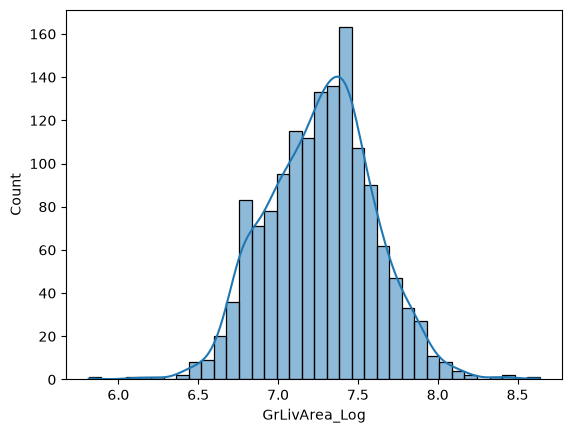

In [19]:
sns.histplot(train['GrLivArea_Log'], kde=True)

print(f'Skeweness: {train['GrLivArea_Log'].skew()}')
print(f'Kurtosis: {train['GrLivArea_Log'].kurt()}')

plt.show()

Skeweness: -0.13740448122837223
Kurtosis: 4.713821643757214


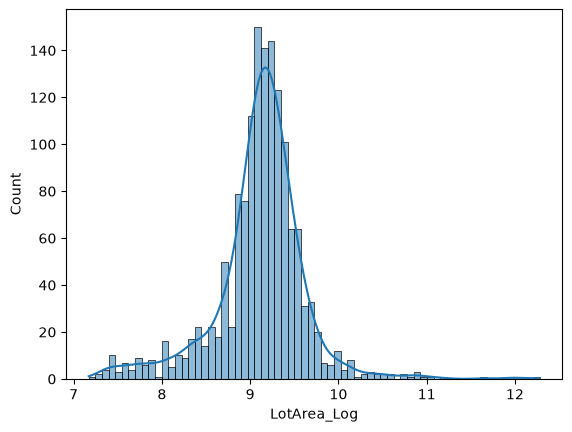

In [20]:
sns.histplot(train['LotArea_Log'], kde=True)

print(f'Skeweness: {train['LotArea_Log'].skew()}')
print(f'Kurtosis: {train['LotArea_Log'].kurt()}')

plt.show()

## Влияние признаков на таргет

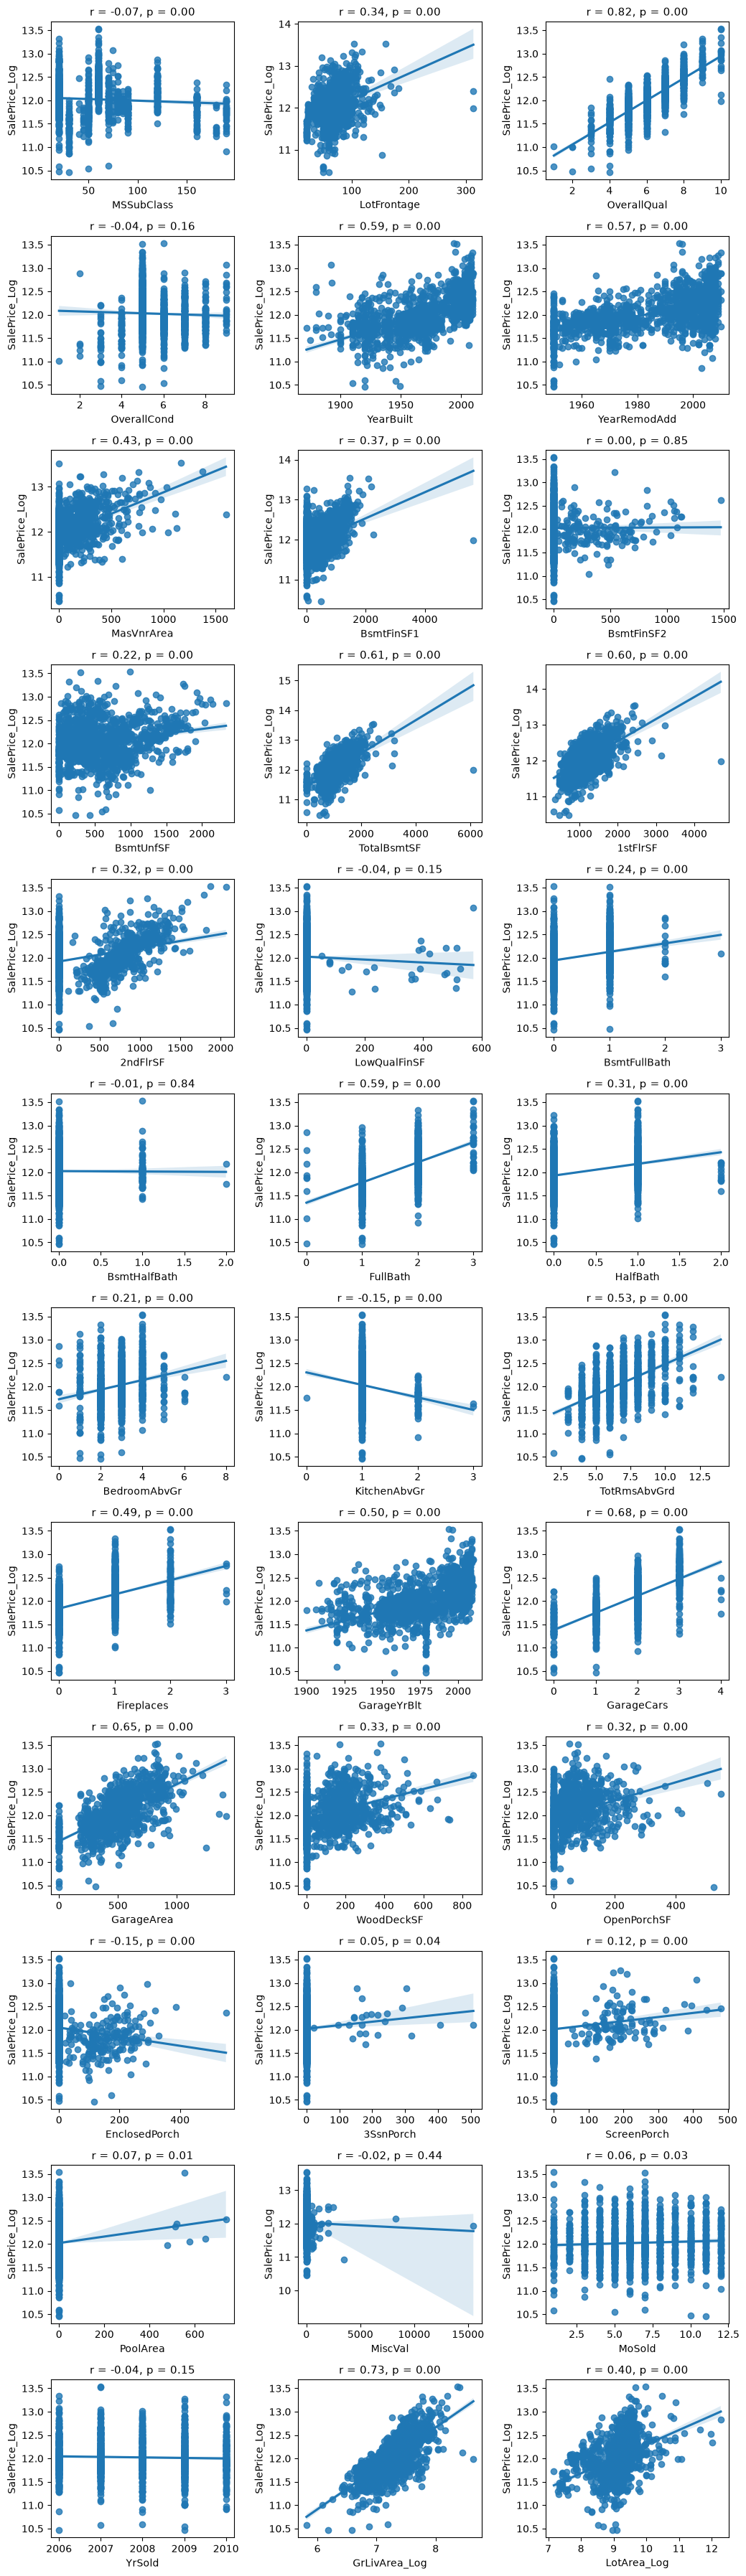

In [21]:
rows = 12
cols = 3

fig, axs = plt.subplots(rows, cols, figsize=(cols*3.5, rows*3))

features_to_plot = [f for f in list(numerical_features) if f not in ['Id', 'SalePrice', 'SalePrice_Log']]

for r in range(0, rows):
    for c in range(0, cols):
        i = r * cols + c

        if i < len(features_to_plot):
            feature = features_to_plot[i]

            sns.regplot(
                x=train[feature],
                y=train[config.general.target],
                ax=axs[r][c]
            )

            stp = stats.pearsonr(
                train[feature],
                train[config.general.target]
            )

            title = f'r = {stp[0]:.2f}, p = {stp[1]:.2f}'
            axs[r][c].set_title(title, fontsize=11)

plt.tight_layout()
plt.show()

Чем больше r отличается от нуля, тем выше линейная корреляция между признаком и таргетом (как, например, у OverallQual (r=0.82)). Для некоторых признаков наблюдается высокая корреляция, для некоторых низкая. Можно ввести порог корреляции, начиная с которого признак будет учитываться моделью при обучении. Назовем его `min_val_corr` и поместим в `config.py`.

Также из графиков выше видно, что некоторые числовые признаки на самом деле являются категориальными (например, MSSubClass, OverallCond и др.)

In [22]:
train = train.drop(train[(train['OverallQual']==10) & (train['SalePrice_Log']<12.3)].index)

In [23]:
train = train.drop(train[(train['GrLivArea_Log']>8.3) & (train['SalePrice_Log']<12.5)].index)

In [24]:
target = config.general.target
corr_threshold = config.general.min_val_corr

corr = train.corr(numeric_only=True)
corr_abs = corr.abs()

num_features_count = len(numerical_features)
ser_corr = corr_abs.nlargest(num_features_count, target)[target]

features_above_threshold = list(ser_corr[ser_corr.values >= corr_threshold].index)
features_below_threshold = list(ser_corr[ser_corr.values < corr_threshold].index)

In [25]:
print("List of numerical features with r above min_val_corr :")
print(features_above_threshold)
print("List of numerical features with r below min_val_corr :")
print(features_below_threshold)

List of numerical features with r above min_val_corr :
['SalePrice_Log', 'OverallQual', 'GrLivArea_Log', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt', 'YearRemodAdd', 'TotRmsAbvGrd', 'GarageYrBlt', 'Fireplaces', 'MasVnrArea', 'LotArea_Log']
List of numerical features with r below min_val_corr :
['BsmtFinSF1', 'LotFrontage', 'WoodDeckSF', 'OpenPorchSF', '2ndFlrSF', 'HalfBath', 'BsmtFullBath', 'BsmtUnfSF', 'BedroomAbvGr', 'EnclosedPorch', 'KitchenAbvGr', 'ScreenPorch', 'PoolArea', 'MSSubClass', 'MoSold', '3SsnPorch', 'LowQualFinSF', 'YrSold', 'OverallCond', 'MiscVal', 'Id', 'BsmtHalfBath', 'BsmtFinSF2']


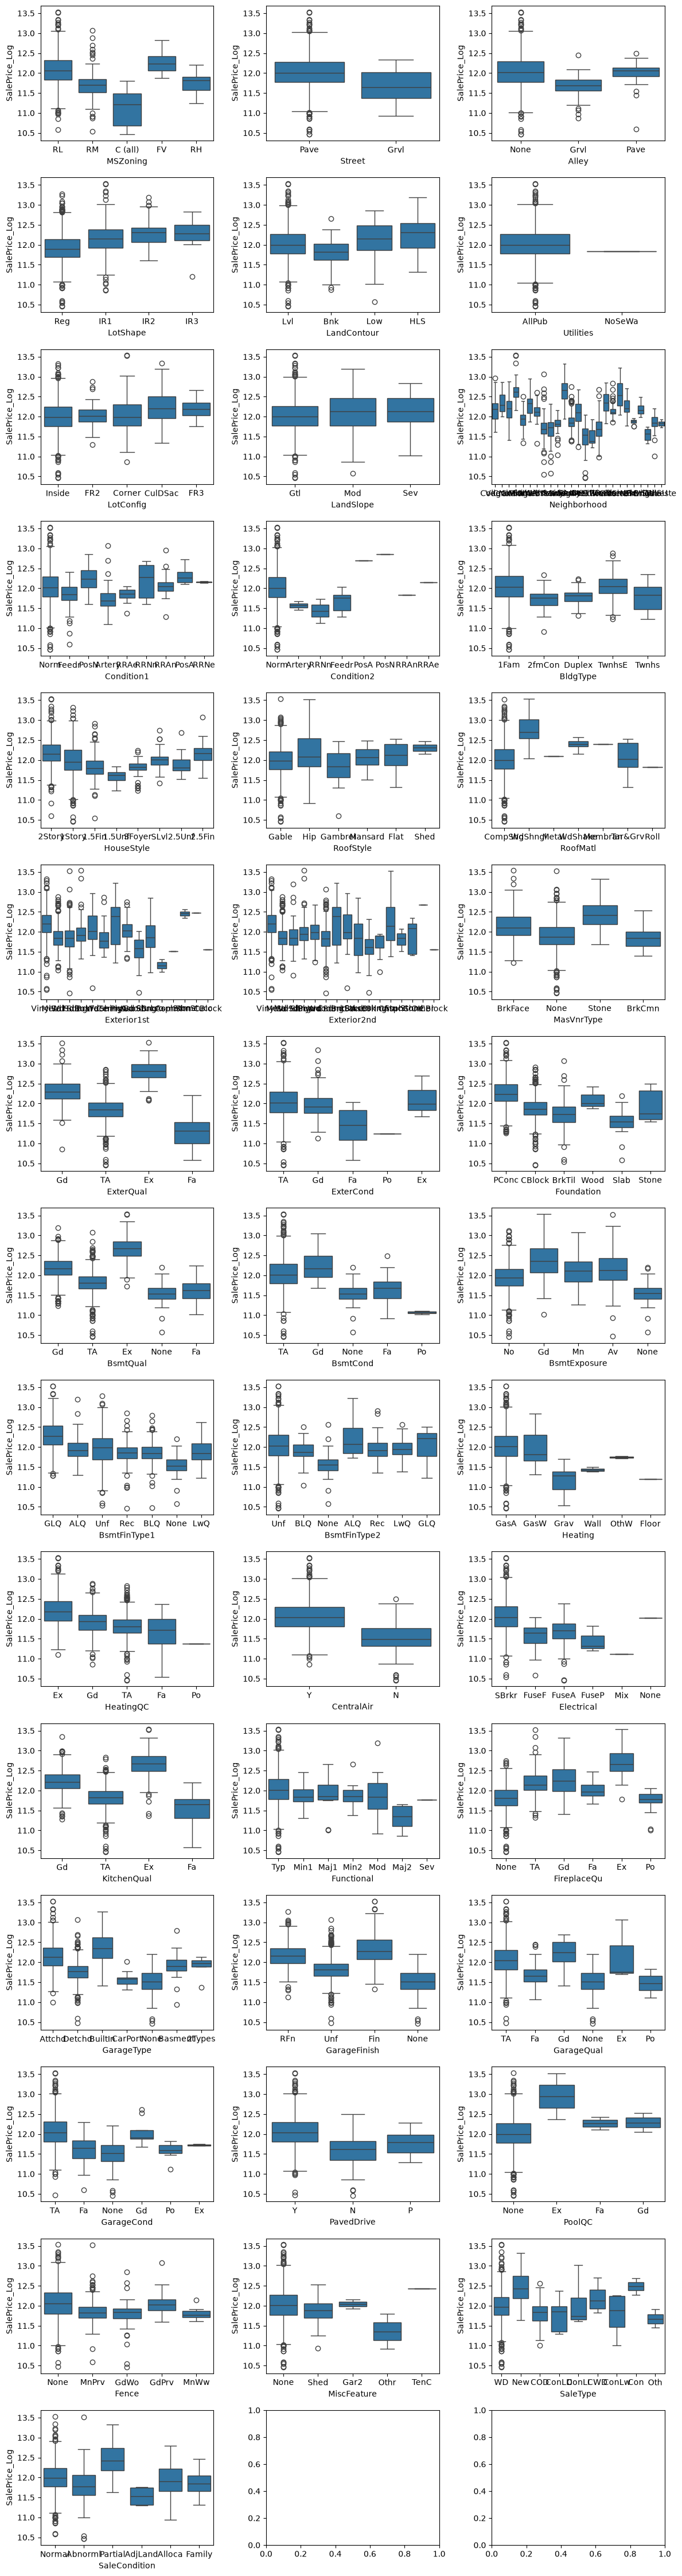

In [26]:
rows = 15
cols = 3

fig, axs = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3))

for r in range(0, rows):
    for c in range(0, cols):
        i = r * cols + c

        if i < len(list(categorical_features)):
            sns.boxplot(x=list(categorical_features)[i], y = config.general.target, data=train, ax=axs[r][c])

plt.tight_layout()
plt.show()

Можно поделить категориальные признаки на признаки с сильной и слабой корреляцией с таргетом:

In [27]:
categorical_strong_corr = [ 'MSZoning', 'Neighborhood', 'Condition2', 'MasVnrType', 'ExterQual', 
                     'BsmtQual','CentralAir', 'Electrical', 'KitchenQual', 'SaleType']

categorical_weak_corr = ['Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 
                  'LandSlope', 'Condition1',  'BldgType', 'HouseStyle', 'RoofStyle', 
                  'RoofMatl', 'Exterior1st', 'Exterior2nd', 'ExterCond', 'Foundation', 
                  'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 
                  'HeatingQC', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 
                  'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 
                  'SaleCondition' ]

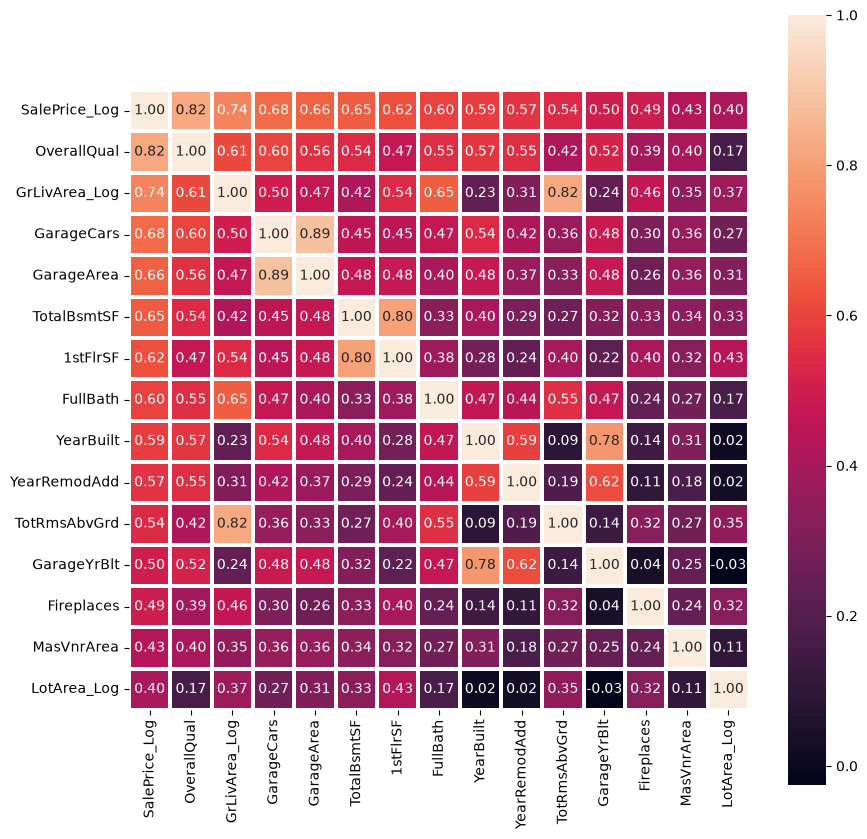

In [28]:
plot_corr_matrix(train, len(features_above_threshold), config.general.target)

Некоторые признаки коррелируют друг с другом. Чтобы избежать мультиколлинеарности, они будут отброшены

In [29]:
features_to_drop = ['Id'] + categorical_weak_corr + features_below_threshold

for df in [train, test]:
    df.drop(features_to_drop, inplace=True, axis=1)

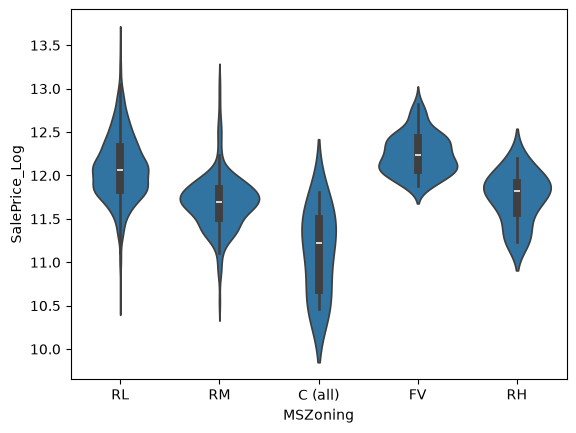

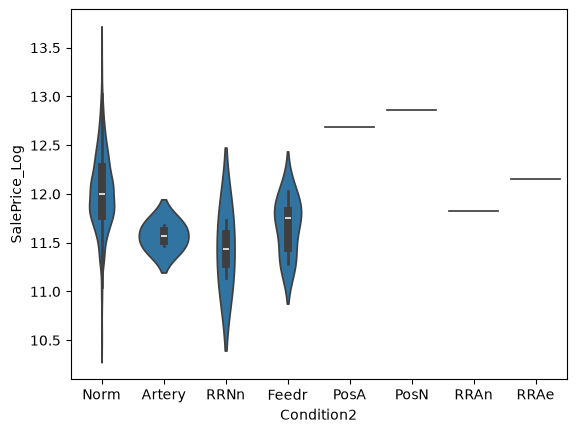

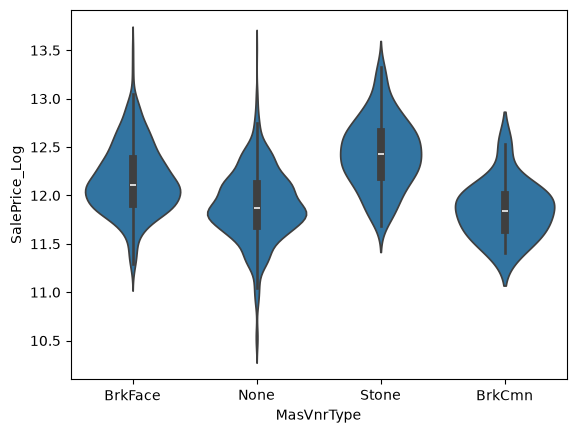

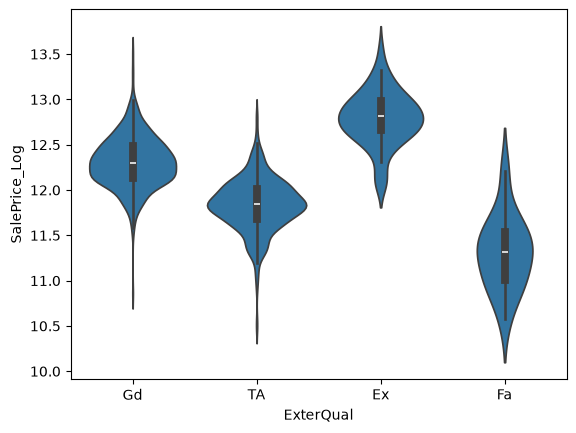

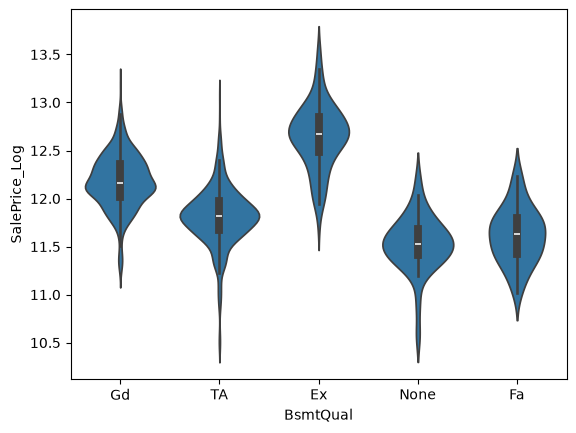

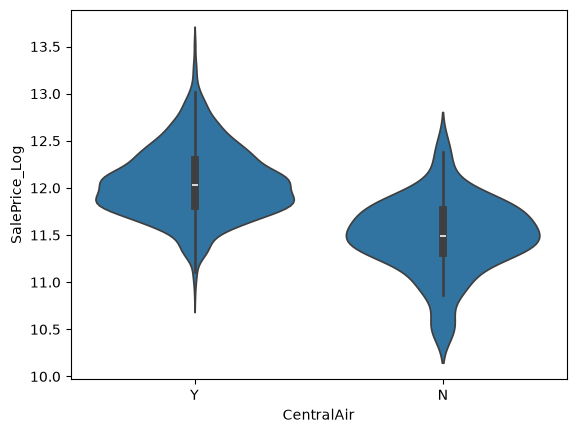

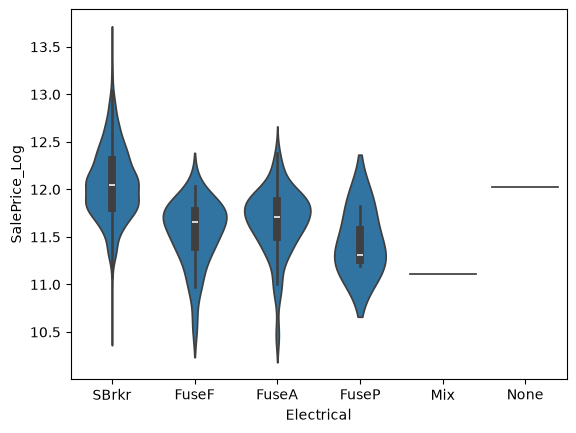

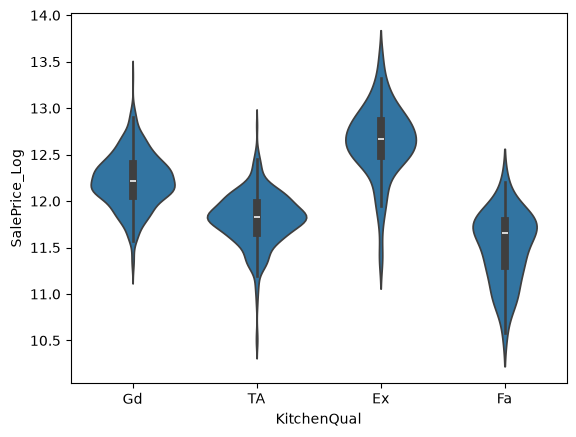

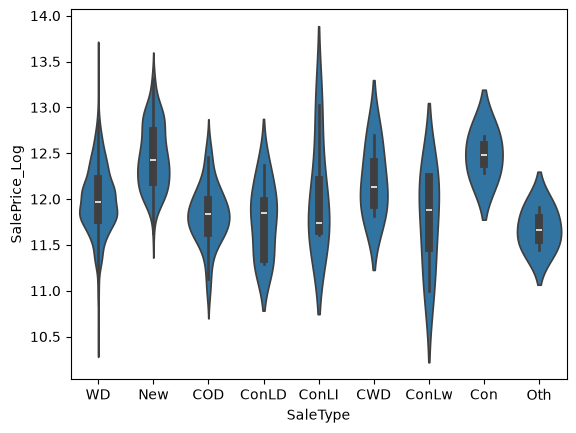

In [31]:
categories = categorical_strong_corr.copy()
categories.remove('Neighborhood')

for cat in categories:
    sns.violinplot(x=cat, y=config.general.target, data=train)
    plt.show()

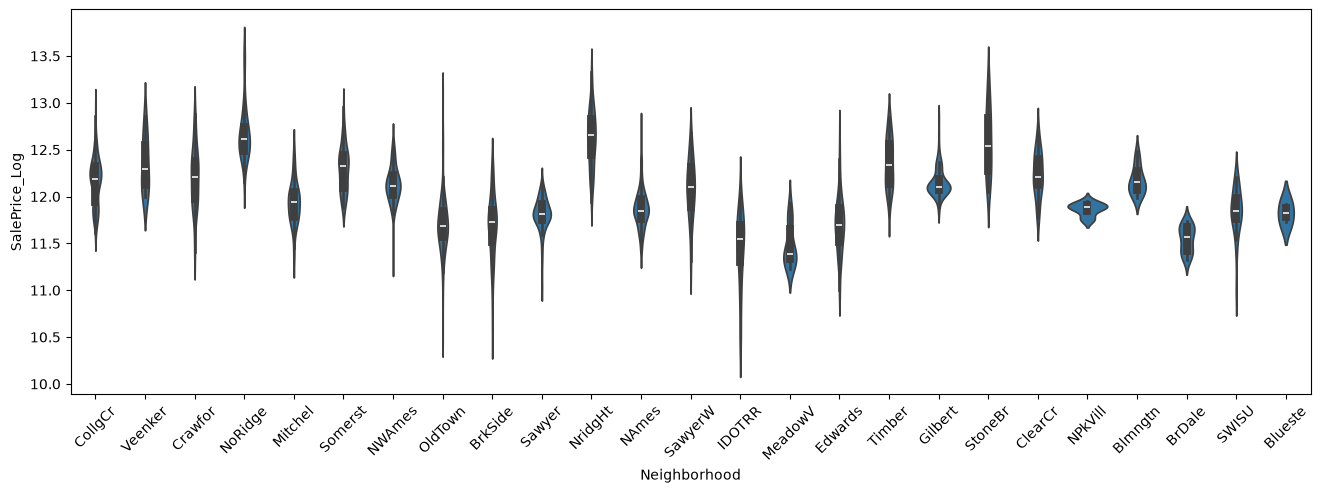

In [32]:
fig, ax = plt.subplots()
fig.set_size_inches(16,5)

sns.violinplot(x='Neighborhood', y = config.general.target, data=train, ax=ax)

plt.xticks(rotation=45)
plt.show()

In [33]:
for cat in categories:
    g = train.groupby(cat)[target].mean()
    print(g)

MSZoning
C (all)    11.118259
FV         12.246616
RH         11.749840
RL         12.085939
RM         11.692893
Name: SalePrice_Log, dtype: float64
Condition2
Artery    11.570036
Feedr     11.670631
Norm      12.025925
PosA      12.691580
PosN      12.860999
RRAe      12.154779
RRAn      11.827043
RRNn      11.435329
Name: SalePrice_Log, dtype: float64
MasVnrType
BrkCmn     11.853239
BrkFace    12.163630
None       11.896884
Stone      12.431016
Name: SalePrice_Log, dtype: float64
ExterQual
Ex    12.792412
Fa    11.304541
Gd    12.311282
TA    11.837985
Name: SalePrice_Log, dtype: float64
BsmtQual
Ex      12.650235
Fa      11.617600
Gd      12.179882
None    11.529680
TA      11.810855
Name: SalePrice_Log, dtype: float64
CentralAir
N    11.491858
Y    12.061099
Name: SalePrice_Log, dtype: float64
Electrical
FuseA    11.660315
FuseF    11.539624
FuseP    11.446808
Mix      11.112448
None     12.028739
SBrkr    12.061474
Name: SalePrice_Log, dtype: float64
KitchenQual
Ex    12.645425
F

На основании близких значений категориальных признаков можем сформировать новые категории:

In [34]:
# 'MSZoning'
msz_catg2 = ['RM', 'RH']
msz_catg3 = ['RL', 'FV'] 


# Neighborhood
nbhd_catg2 = ['Blmngtn', 'ClearCr', 'CollgCr', 'Crawfor', 'Gilbert', 'NWAmes', 'Somerst', 'Timber', 'Veenker']
nbhd_catg3 = ['NoRidge', 'NridgHt', 'StoneBr']

# Condition2
cond2_catg2 = ['Norm', 'RRAe']
cond2_catg3 = ['PosA', 'PosN'] 

# SaleType
SlTy_catg1 = ['Oth']
SlTy_catg3 = ['CWD']
SlTy_catg4 = ['New', 'Con']

In [35]:
for df in [train, test]:
    
    df['MSZ_num'] = 1  
    df.loc[(df['MSZoning'].isin(msz_catg2) ), 'MSZ_num'] = 2    
    df.loc[(df['MSZoning'].isin(msz_catg3) ), 'MSZ_num'] = 3        
    
    df['NbHd_num'] = 1       
    df.loc[(df['Neighborhood'].isin(nbhd_catg2) ), 'NbHd_num'] = 2    
    df.loc[(df['Neighborhood'].isin(nbhd_catg3) ), 'NbHd_num'] = 3    

    df['Cond2_num'] = 1       
    df.loc[(df['Condition2'].isin(cond2_catg2) ), 'Cond2_num'] = 2    
    df.loc[(df['Condition2'].isin(cond2_catg3) ), 'Cond2_num'] = 3    
    
    df['Mas_num'] = 1       
    df.loc[(df['MasVnrType'] == 'Stone' ), 'Mas_num'] = 2 
    
    df['ExtQ_num'] = 1       
    df.loc[(df['ExterQual'] == 'TA' ), 'ExtQ_num'] = 2     
    df.loc[(df['ExterQual'] == 'Gd' ), 'ExtQ_num'] = 3     
    df.loc[(df['ExterQual'] == 'Ex' ), 'ExtQ_num'] = 4 

    df['BsQ_num'] = 1          
    df.loc[(df['BsmtQual'] == 'Gd' ), 'BsQ_num'] = 2     
    df.loc[(df['BsmtQual'] == 'Ex' ), 'BsQ_num'] = 3     
 
    df['CA_num'] = 0          
    df.loc[(df['CentralAir'] == 'Y' ), 'CA_num'] = 1    

    df['Elc_num'] = 1       
    df.loc[(df['Electrical'] == 'SBrkr' ), 'Elc_num'] = 2 


    df['KiQ_num'] = 1       
    df.loc[(df['KitchenQual'] == 'TA' ), 'KiQ_num'] = 2     
    df.loc[(df['KitchenQual'] == 'Gd' ), 'KiQ_num'] = 3     
    df.loc[(df['KitchenQual'] == 'Ex' ), 'KiQ_num'] = 4      
    
    df['SlTy_num'] = 2       
    df.loc[(df['SaleType'].isin(SlTy_catg1) ), 'SlTy_num'] = 1  
    df.loc[(df['SaleType'].isin(SlTy_catg3) ), 'SlTy_num'] = 3  
    df.loc[(df['SaleType'].isin(SlTy_catg4) ), 'SlTy_num'] = 4  

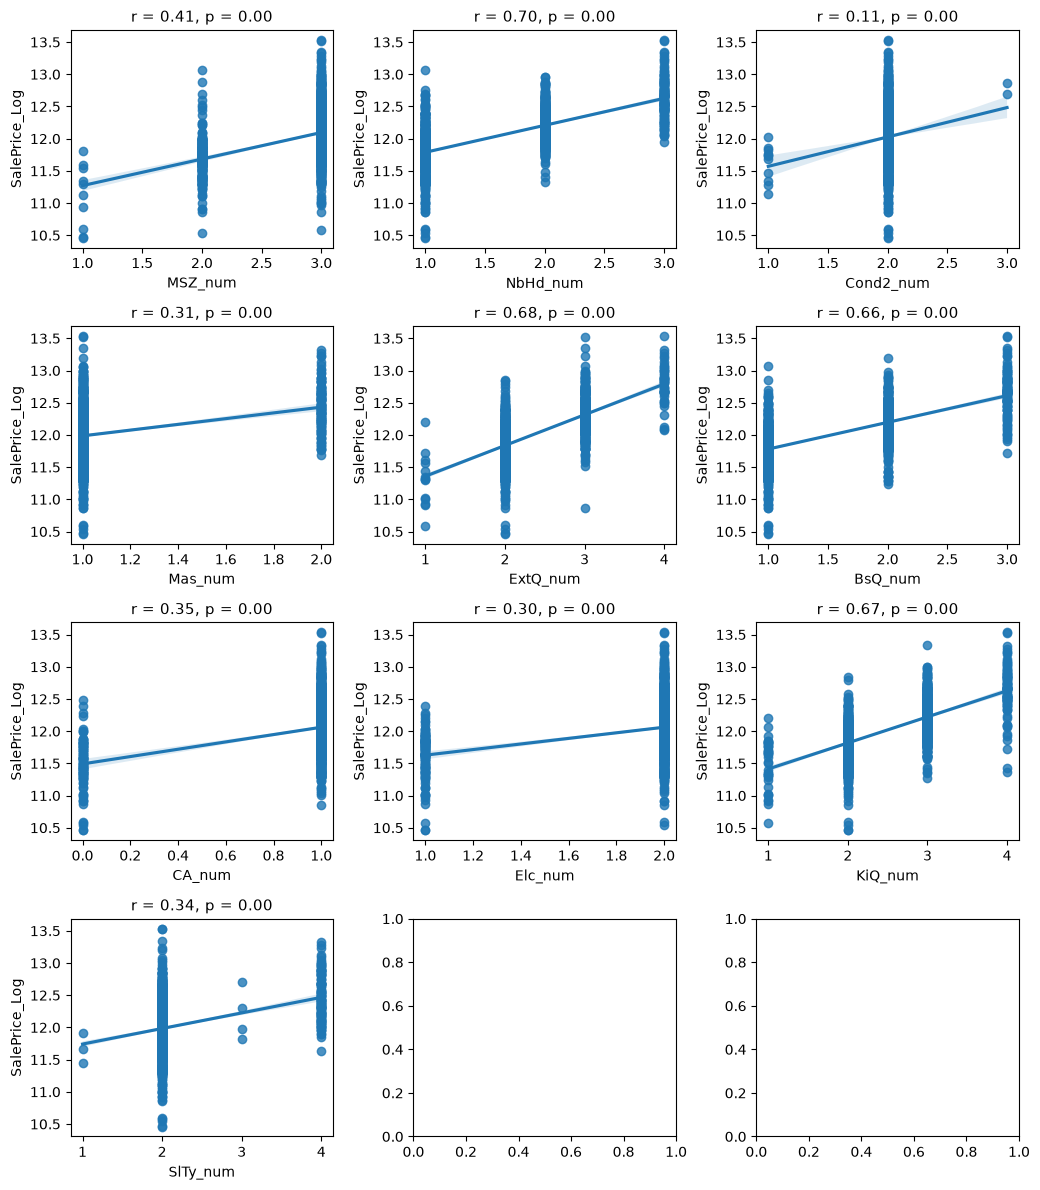

In [37]:
new_numerical_features = ['MSZ_num', 'NbHd_num', 'Cond2_num', 'Mas_num', 'ExtQ_num', 'BsQ_num', 'CA_num', 'Elc_num', 'KiQ_num', 'SlTy_num']

rows = 4
cols = 3

fig, axs = plt.subplots(rows, cols, figsize=(cols*3.5, rows*3))

for r in range(0, rows):
    for c in range(0, cols):
        i = r * cols + c

        if i < len(new_numerical_features):
            sns.regplot(
                x=train[new_numerical_features[i]],
                y=train[config.general.target],
                ax=axs[r][c]
            )

            stp = stats.pearsonr(
                train[new_numerical_features[i]],
                train[config.general.target]
            )

            title = f'r = {stp[0]:.2f}, p = {stp[1]:.2f}'
            axs[r][c].set_title(title, fontsize=11)

plt.tight_layout()
plt.show()

Наблюдается достаточно высокая корреляция между новыми признаками и таргетом (NbHd_num, ExtQ_num, BsQ_num, KiQ_num)

In [39]:
categorical_cols_to_drop = ['Neighborhood' , 'Condition2', 'MasVnrType', 'ExterQual', 'BsmtQual','CentralAir', 'Electrical', 'KitchenQual', 'SaleType']

corr1 = train.corr(numeric_only=True)
corr_abs_1 = corr1.abs()

nr_all_cols = len(train)
ser_corr_1 = corr_abs_1.nlargest(nr_all_cols, target)[target]

print(ser_corr_1)
cols_bel_corr_limit_1 = list(ser_corr_1[ser_corr_1.values <= config.general.min_val_corr].index)


for df in [train, test] :
    df.drop(categorical_cols_to_drop, inplace= True, axis = 1)
    df.drop(cols_bel_corr_limit_1, inplace= True, axis = 1) 

SalePrice_Log    1.000000
OverallQual      0.821404
GrLivArea_Log    0.737431
NbHd_num         0.696962
ExtQ_num         0.682225
GarageCars       0.681033
KiQ_num          0.669989
BsQ_num          0.661286
GarageArea       0.656128
TotalBsmtSF      0.647563
1stFlrSF         0.620500
FullBath         0.595899
YearBuilt        0.587043
YearRemodAdd     0.565992
TotRmsAbvGrd     0.537702
GarageYrBlt      0.500842
Fireplaces       0.491998
MasVnrArea       0.433353
MSZ_num          0.409423
LotArea_Log      0.402820
CA_num           0.351598
SlTy_num         0.337469
Mas_num          0.313280
Elc_num          0.304857
Cond2_num        0.107610
Name: SalePrice_Log, dtype: float64


После удаления признаков с низкой корреляцией:

In [40]:
corr2 = train.corr(numeric_only=True)
corr_abs_2 = corr2.abs()

nr_all_cols = len(train)
ser_corr_2 = corr_abs_2.nlargest(nr_all_cols, target)[target]

print(ser_corr_2)

SalePrice_Log    1.000000
OverallQual      0.821404
GrLivArea_Log    0.737431
NbHd_num         0.696962
ExtQ_num         0.682225
GarageCars       0.681033
KiQ_num          0.669989
BsQ_num          0.661286
GarageArea       0.656128
TotalBsmtSF      0.647563
1stFlrSF         0.620500
FullBath         0.595899
YearBuilt        0.587043
YearRemodAdd     0.565992
TotRmsAbvGrd     0.537702
GarageYrBlt      0.500842
Fireplaces       0.491998
MasVnrArea       0.433353
MSZ_num          0.409423
LotArea_Log      0.402820
Name: SalePrice_Log, dtype: float64


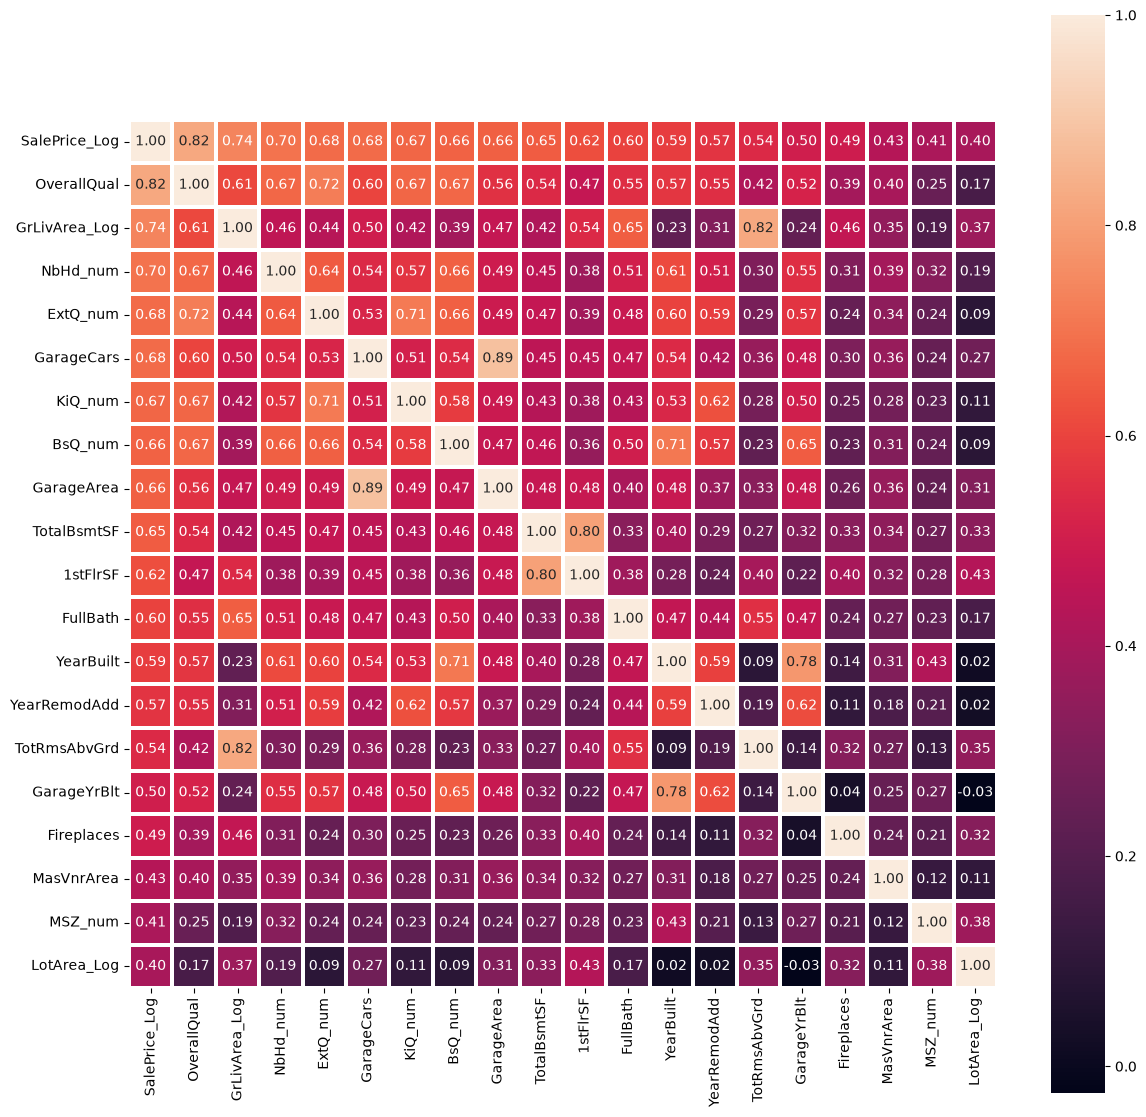

In [41]:
plot_corr_matrix(train, len(train.columns), target)

Между признаками GrLivArea_Log - TotRmsAbvGrd, GarageCars - GarageArea, TotalBsmtSF - 1stFlrSF, YearBuilt - GarageYrBlt наблюдается сильная корреляция. Из них можно удалить те, у которых корреляция с таргетом меньше

In [47]:
cols = corr_abs_2.nlargest(nr_all_cols, target)[target].index
cols = list(cols)

if config.general.drop_similar == True :
    for col in ['GarageArea','1stFlrSF','TotRmsAbvGrd','GarageYrBlt'] :
        if col in cols: 
            cols.remove(col)

In [48]:
cols

['SalePrice_Log',
 'OverallQual',
 'GrLivArea_Log',
 'NbHd_num',
 'ExtQ_num',
 'GarageCars',
 'KiQ_num',
 'BsQ_num',
 'TotalBsmtSF',
 'FullBath',
 'YearBuilt',
 'YearRemodAdd',
 'Fireplaces',
 'MasVnrArea',
 'MSZ_num',
 'LotArea_Log']

In [49]:
features = cols.copy()
features.remove('SalePrice_Log')

features

['OverallQual',
 'GrLivArea_Log',
 'NbHd_num',
 'ExtQ_num',
 'GarageCars',
 'KiQ_num',
 'BsQ_num',
 'TotalBsmtSF',
 'FullBath',
 'YearBuilt',
 'YearRemodAdd',
 'Fireplaces',
 'MasVnrArea',
 'MSZ_num',
 'LotArea_Log']